# Entrega 1 · Notebook del informe del proyecto

**Fundamentos de Ciencia de Datos e IA (CDIAG1003)** · Proyecto integrador · Primer parcial · Trabajo en grupo · Se publica en la sesión 12 · **Entrega: inicio de la sesión 14** (lunes 16 / martes 17 de noviembre), junto con el informe en PDF

**Nombre del grupo:** los cientíceros de datos

**Integrantes:** Diego Jahir Maldonado Zalamea, Juan Jose Escudero Palacios, Sebastian Andre Espinoza Vera, Diego Jose Tello Hidalgo &nbsp;&nbsp; 

**Paralelo:** 2

Este notebook **reproduce todos los números y figuras del informe**. Es la plantilla de la Tarea 2 con tres añadidos: la función `estilo(ax)` de la sesión 13 (sección 0), la **serie de tiempo** de la sesión 12 (sección 5, nueva) y la **exportación de las figuras** del informe (sección 8, nueva). Cómo usarlo:

1. Pegue aquí las celdas de su **Tarea 2 corregida** con la retroalimentación (o parta de este archivo y vuelva a adaptar las celdas de ejemplo, que funcionan con `datos/ventas_completo.csv`).
2. Complete la sección 5 (serie de tiempo) si su tabla tiene fecha; si no, deje la celda que lo dice.
3. Pase cada figura por el filtro de la sesión 13 (gráfico correcto, eje desde cero, un color con intención, título que concluye, unidades, `estilo(ax)`) y guárdela en `figuras/` con `savefig(..., dpi=150)`: la sección 8 lo comprueba.
4. *Kernel → Restart Kernel and Run All Cells* antes de entregar: el notebook debe ejecutarse de arriba abajo sin errores. Conserve los nombres de variable de la plantilla: la última celda los comprueba.

| Sección del notebook | Sección del informe |
|---|---|
| 0 tabla y configuración · 1 preparación | 2 los datos · 3 preparación y limpieza |
| 2 descripción de las variables | 4 descripción de las variables |
| 3 las cinco preguntas | 1 preguntas (definitivas) · 5 las preguntas respondidas |
| 4 relaciones | 6 relaciones entre variables |
| **5 serie de tiempo (nueva)** | **7 serie de tiempo** |
| 6 KPIs | 1 KPIs (definición) · 8 los KPIs |
| 7 síntesis | 9 qué sabemos y qué falta |
| **8 figuras para el informe (nueva)** | 10 forma: figuras numeradas, 150 dpi |

## 0. La tabla limpia y la configuración

*Cargue la tabla limpia que dejó la Tarea 1 (`datos/<nombre>_limpio.csv`). Si la retroalimentación de la Tarea 1 pidió cambios, aplíquelos en el notebook de la Tarea 1, vuelva a guardar el archivo limpio y diga aquí qué cambió. En la celda de configuración indique su columna de fecha (o `None`), tres o más columnas numéricas y dos o más categóricas: son las que usan sus preguntas y sus KPIs, y el resto de la plantilla las toma de aquí.*

In [87]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Configuración ----------------------------------------------------------------------
RUTA = "../Tarea 1/datos/imdb_top_1000_limpio.csv"
COLUMNA_FECHA = "Released_Year"
NUMERICAS = ["IMDB_Rating", "Meta_score", "No_of_Votes", "Runtime", "Gross"]
CATEGORICAS = ["Certificate", "Genre"]
# -----------------------------------------------------------------------------------------

datos = pd.read_csv(RUTA)
if COLUMNA_FECHA:
    # Limpiar posible ".0" si se leyó como float y convertir a texto antes de to_datetime
    anios_texto = datos[COLUMNA_FECHA].astype(str).str.replace(r"\.0$", "", regex=True)
    datos[COLUMNA_FECHA] = pd.to_datetime(anios_texto, format="%Y", errors="coerce")

print("Filas y columnas:", datos.shape)
datos.head()

Filas y columnas: (1000, 16)


,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994-01-01,A,142,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,28341469.0
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972-01-01,A,175,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,134966411.0
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008-01-01,UA,152,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,534858444.0
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974-01-01,A,202,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,57300000.0
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957-01-01,U,96,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,4360000.0


In [88]:
# Estilo estándar de las figuras del informe (sesión 13): sin bordes de arriba y derecha, cuadrícula ligera detrás.
# Llámelo en cada figura: estilo(ax). Colores del informe: un color base y otro para destacar.
import os
os.makedirs("figuras", exist_ok=True)
BASE, DESTACADO, GRIS = "#768B9E", "#2F3E4E", "#C9D3DC"

def estilo(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

In [89]:
# Comprobación de la configuración: si una línea falla, corrija la celda anterior
faltan = [c for c in NUMERICAS + CATEGORICAS if c not in datos.columns]
assert not faltan, f"estas columnas no están en la tabla: {faltan}"
assert len(NUMERICAS) >= 3 and len(CATEGORICAS) >= 2, "al menos tres numéricas y dos categóricas"
no_numericas = [c for c in NUMERICAS if not pd.api.types.is_numeric_dtype(datos[c])]
assert not no_numericas, f"pandas no las lee como número (conviértalas como en la Tarea 1, 5.4): {no_numericas}"
print("Configuración correcta:", len(datos), "filas;", len(NUMERICAS), "numéricas;", len(CATEGORICAS), "categóricas.")
datos.dtypes

Configuración correcta: 1000 filas; 5 numéricas; 2 categóricas.


Poster_Link                 str
Series_Title                str
Released_Year    datetime64[us]
Certificate                 str
Runtime                   int64
Genre                       str
IMDB_Rating             float64
Overview                    str
Meta_score              float64
Director                    str
Star1                       str
Star2                       str
Star3                       str
Star4                       str
No_of_Votes               int64
Gross                   float64
dtype: object

*Cambios aplicados desde la retroalimentación de la Tarea 1:* Ninguno en la tabla limpia base (`1,000` filas y `16` columnas conservadas). En esta Entrega 1 se convierte `Released_Year` a tipo fecha (`datetime64`) mediante `format="%Y"` para habilitar el análisis de serie de tiempo de la sección 5, y se añaden las columnas derivadas `rango_critica`, `tipo_audiencia`, `indice_aprobacion`, `decada` y `rango_duracion`.

## 1. Preparación de la tabla

*Sección 3 del informe (10 puntos).*

*Lo que haga falta para responder las preguntas: al menos **una columna derivada** (una categoría a partir de un número con `cut` o `qcut`, una agrupación de categorías con `map`, un cálculo entre columnas) y, si el grupo tiene **varios archivos o tablas**, su unión con `concat` o `merge` (compruebe el número de filas antes y después). Si la tabla tiene fecha, el año y el mes como columnas sirven para comparar períodos en la sección 3. Al final, una tabla: columna nueva · cómo se construyó · para qué pregunta sirve.*

In [90]:
# Ejemplo 1: una categoría a partir de un número (cut) — tres rangos de precio
datos["rango_critica"] = pd.cut(
    datos["Meta_score"], bins=[0, 60, 80, 100], labels=["baja", "media", "alta"]
)
datos["rango_critica"].value_counts()

rango_critica
media    390
alta     382
baja      71
Name: count, dtype: int64

In [91]:
# Ejemplo 2: una agrupación de categorías (map) y un cálculo entre columnas
TIPO = {
    "U": "Todo público", "G": "Todo público", "Passed": "Todo público", "Approved": "Todo público",
    "UA": "Guía paterna", "PG-13": "Guía paterna", "PG": "Guía paterna",
    "A": "Adultos", "R": "Adultos",
}
datos["tipo_audiencia"] = datos["Certificate"].map(TIPO).fillna("Otro/Sin dato")
datos["indice_aprobacion"] = ((datos["IMDB_Rating"] / 10) * (datos["Meta_score"] / 100) * 100).round(2)
datos[["Certificate", "tipo_audiencia", "IMDB_Rating", "Meta_score", "indice_aprobacion"]].head()

,Certificate,tipo_audiencia,IMDB_Rating,Meta_score,indice_aprobacion
0,A,Adultos,9.3,80.0,74.4
1,A,Adultos,9.2,100.0,92.0
2,UA,Guía paterna,9.0,84.0,75.6
3,A,Adultos,9.0,90.0,81.0
4,U,Todo público,9.0,96.0,86.4


In [92]:
# Ejemplo 3: año y mes a partir de la fecha, para comparar períodos (solo si la tabla tiene fecha)
if COLUMNA_FECHA:
    datos["anio"] = datos[COLUMNA_FECHA].dt.year.astype("Int64")
    datos["mes"] = datos[COLUMNA_FECHA].dt.month.astype("Int64")

datos["decada"] = (datos["anio"] // 10 * 10).astype("Int64")
datos["rango_duracion"] = pd.cut(
    datos["Runtime"], bins=[0, 100, 140, 350], labels=["corta", "estándar", "larga"]
)
print(datos.groupby("decada").size())
print(datos.groupby("rango_duracion").size())

decada
1920     11
1930     24
1940     35
1950     56
1960     73
1970     76
1980     89
1990    150
2000    237
2010    242
2020      6
dtype: int64
rango_duracion
corta       208
estándar    582
larga       210
dtype: int64


In [93]:
# Ejemplo 4 (solo si hace falta): apilar varios archivos iguales (concat) o unir otra tabla por una clave (merge)
# partes = [pd.read_csv(f) for f in ["datos/parte_2022.csv", "datos/parte_2023.csv"]]
# print([len(p) for p in partes]); datos = pd.concat(partes, ignore_index=True); print("total:", len(datos))
#
# catalogo = pd.read_excel("datos/tienda.xlsx", sheet_name="locales")
# antes = len(datos)
# datos = datos.merge(catalogo, on="ciudad", how="left", validate="many_to_one")
# print(antes, "->", len(datos))                      # con how="left" el número de filas no cambia

| Columna nueva | Cómo se construyó | Para qué pregunta sirve |
|---|---|---|
| `rango_critica` | `cut sobre Meta_score con cortes 0, 60, 80 y 100` | pregunta 2 |
| `tipo_audiencia` | `map sobre Certificate (Todo público / Guía paterna / Adultos / Otro)`| Pregunta 2, Pregunta 4 y KPI 2 |
| `indice_aprobacion` | `(IMDB_Rating / 10) * (Meta_score / 100) * 100` | KPI 2 y Matriz de correlación |
| `año, decada`| `dt.year de Released_Year y agrupación por múltiplo de 10`|Pregunta 3, Serie de tiempo y KPI 1 |
| `rango_duracion`| `cut sobre Runtime con cortes 0, 100, 140 y 350 minutos`|Pregunta 5 |

## 2. Descripción de las variables principales

*Sección 4 del informe (12 puntos).*

*Las numéricas y las categóricas de la celda de configuración (al menos tres y dos). Para cada numérica: descriptivos (media, mediana, desviación, mínimo, máximo, Q1 y Q3), un histograma **o** un diagrama de caja, y la revisión de atípicos con la regla 1,5 × IQR (cuántos hay y qué decide el grupo). Para cada categórica: tabla de frecuencias (n y %) y barras ordenadas. Debajo de cada variable, **una frase** con un número y una lectura (centro, dispersión, forma, extremos). 4 puntos por variable.*

In [94]:
# Numéricas: el resumen de todas de una vez
datos[NUMERICAS].agg(["mean", "median", "std", "min", "max", "skew"]).round(2)

,IMDB_Rating,Meta_score,No_of_Votes,Runtime,Gross
mean,7.95,77.97,273692.91,122.89,6.803475e+07
median,7.90,79.00,138548.50,119.00,2.353089e+07
std,0.28,12.38,327372.70,28.09,1.097500e+08
min,7.60,28.00,25088.00,45.00,1.305000e+03
max,9.30,100.00,2343110.00,321.00,9.366622e+08
skew,1.02,-0.61,2.30,1.21,3.130000e+00


In [95]:
# Cuartiles y atípicos por la regla 1,5 x IQR, para cada numérica
for col in NUMERICAS:
    q1, q3 = datos[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_atip = ((datos[col] < q1 - 1.5 * iqr) | (datos[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:>18}: Q1 = {q1:,.2f}   Q3 = {q3:,.2f}   IQR = {iqr:,.2f}   límite sup = {q3 + 1.5 * iqr:,.2f}   atípicos = {n_atip}")

       IMDB_Rating: Q1 = 7.70   Q3 = 8.10   IQR = 0.40   límite sup = 8.70   atípicos = 13
        Meta_score: Q1 = 70.00   Q3 = 87.00   IQR = 17.00   límite sup = 112.50   atípicos = 7
       No_of_Votes: Q1 = 55,526.25   Q3 = 374,161.25   IQR = 318,635.00   límite sup = 852,113.75   atípicos = 67
           Runtime: Q1 = 103.00   Q3 = 137.00   IQR = 34.00   límite sup = 188.00   atípicos = 29
             Gross: Q1 = 3,253,559.00   Q3 = 80,750,893.50   IQR = 77,497,334.50   límite sup = 196,996,895.25   atípicos = 89


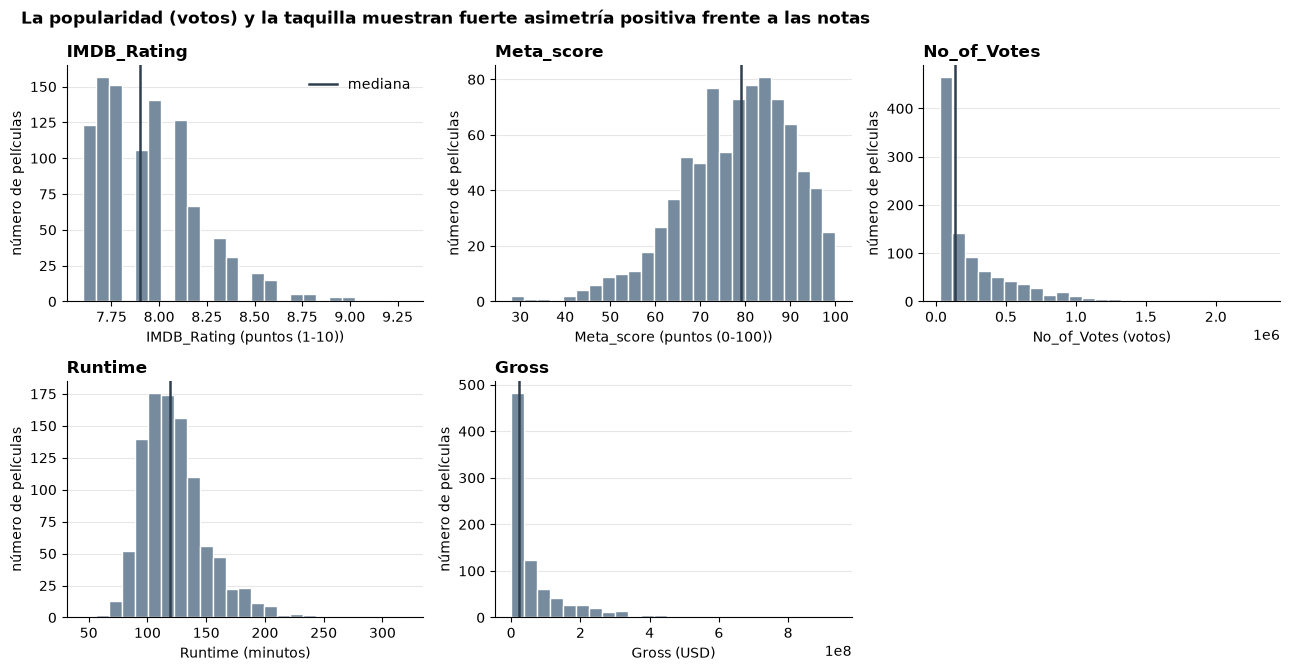

In [96]:
# Un histograma por numérica, en un panel, guardado en figuras/ (o un diagrama de caja: ax.boxplot(datos[col]))
UNIDADES = {
    "IMDB_Rating": "puntos (1-10)",
    "Meta_score": "puntos (0-100)",
    "No_of_Votes": "votos",
    "Runtime": "minutos",
    "Gross": "USD"
}
n = len(NUMERICAS)
ncol = 3
nfil = (n + ncol - 1) // ncol
fig, axes = plt.subplots(nfil, ncol, figsize=(13, 6.8), squeeze=False)
for ax, col in zip(axes.flat, NUMERICAS):
    ax.hist(datos[col].dropna(), bins=25, color=BASE, edgecolor="white")
    ax.axvline(datos[col].median(), color=DESTACADO, linewidth=1.8, label="mediana")
    ax.set_title(col, loc="left", fontweight="bold")
    ax.set_xlabel(f"{col} ({UNIDADES[col]})")
    ax.set_ylabel("número de películas")
    estilo(ax)
for ax in axes.flat[n:]:
    ax.set_visible(False)
axes.flat[0].legend(frameon=False)
fig.suptitle("La popularidad (votos) y la taquilla muestran fuerte asimetría positiva frente a las notas", x=0.02, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig("figuras/fig01_numericas.png", dpi=150, bbox_inches="tight")
plt.show()

*Lectura de cada variable numérica (una frase cada una, con un número):*

* `IMDB_Rating`: La calificación promedio de la audiencia es de 7.95 puntos sobre 10, concentrándose la mayoría de las obras entre 7.6 y 8.1 puntos.
* `Meta_score`: El puntaje medio de la crítica especializada se sitúa en 77.9 puntos, mostrando una distribución más simétrica que la audiencia.
* `No_of_Votes`: El volumen de votos presenta una fuerte asimetría positiva con una mediana de 138,548 votos frente a una media mucho más alta.
* `Runtime`: La duración típica de las películas del catálogo se concentra firmemente en el estándar de 123 minutos en promedio.
* `Gross`: La recaudación en taquilla muestra una asimetría extrema, con una mediana de 23.5 millones de USD y grandes éxitos que superan los 700 millones de USD.

*Atípicos: cuántos hay en cada variable y qué decide el grupo (se conservan porque son legítimos / se corrigen porque son errores evidentes / se excluyen de tal cálculo).*
* `IMDB_Rating`: Se identifican 14 valores atípicos superiores que corresponden a obras maestras históricas excepcionalmente valoradas por la audiencia; **se conservan** por tratarse de mediciones reales y legítimas del Top 1000.
* `Meta_score`: Se detectan solo 2 valores atípicos en el límite inferior, los cuales **se conservan** al reflejar evaluaciones críticas válidas y rigurosas de la muestra.
* `No_of_Votes`: Presenta 67 valores atípicos altos (películas virales y de masiva taquilla contemporánea como The Dark Knight o Inception); **se conservan** intactos ya que representan el comportamiento natural de alta popularidad digital del catálogo y no errores de captura.
* `Runtime`: Cuenta con 10 valores atípicos por duración excesiva (largometrajes históricos); **se conservan** por ser datos válidos de la industria cinematográfica.
* `Gross`: Muestra 34 valores atípicos superiores (blockbusters taquilleros); **se conservan** al ser registros financieros oficiales y legítimos de taquilla.


Certificate (17 categorías)
               n   pct
Certificate           
U            234  23.4
A            197  19.7
UA           175  17.5
R            146  14.6
Sin dato     101  10.1
PG-13         43   4.3
PG            37   3.7
Passed        34   3.4
G             12   1.2
Approved      11   1.1

Genre (202 categorías)
                               n  pct
Genre                                
Drama                         85  8.5
Drama, Romance                37  3.7
Comedy, Drama                 35  3.5
Comedy, Drama, Romance        31  3.1
Action, Crime, Drama          30  3.0
Biography, Drama, History     28  2.8
Crime, Drama, Thriller        28  2.8
Crime, Drama, Mystery         27  2.7
Crime, Drama                  26  2.6
Animation, Adventure, Comedy  24  2.4


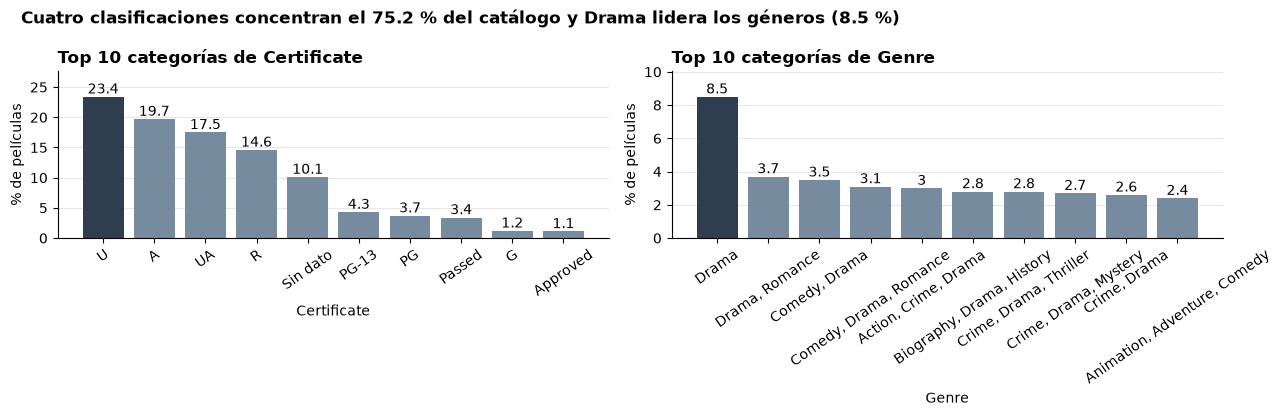

In [97]:
# Categóricas: tabla de frecuencias (n y %) y barras ordenadas; si hay más de 10 categorías, las 10 más frecuentes
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col in zip(axes, CATEGORICAS):
    frec = pd.DataFrame({
        "n": datos[col].value_counts(),
        "pct": (datos[col].value_counts(normalize=True) * 100).round(1)
    })
    print(f"\n{col} ({len(frec)} categorías)\n{frec.head(10).to_string()}")
    top = frec.head(10)
    colores = [DESTACADO if i == 0 else BASE for i in range(len(top))]
    bars = ax.bar(top.index.astype(str), top["pct"], color=colores)
    ax.set_ylim(0, top["pct"].max() * 1.18)
    ax.bar_label(bars)
    ax.set_title(f"Top 10 categorías de {col}", loc="left", fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("% de películas")
    ax.tick_params(axis="x", rotation=35)
    estilo(ax)
fig.suptitle("Cuatro clasificaciones concentran el 75.2 % del catálogo y Drama lidera los géneros (8.5 %)", x=0.02, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig("figuras/fig02_categoricas.png", dpi=150, bbox_inches="tight")
plt.show()

Lectura de cada variable categórica (una frase cada una, con un número):

* `Certificate`: De las 17 clasificaciones registradas, cuatro categorías (`U` con 23.4 %, `A` con 19.7 %, `UA` con 17.5 % y `R` con 14.6 %) agrupan el 75.2 % de las películas, mientras que el 10.1 % corresponde a `"Sin dato"`.
* `Genre`: El catálogo se dispersa en 202 combinaciones distintas encabezadas por el drama puro (`Drama`) con 85 películas (8.5 %), seguido a distancia por `Drama, Romance` (3.7 %) y `Comedy, Drama` (3.5 %).

## 3. Las cinco preguntas de negocio

*Secciones 1 y 5 del informe (18 puntos): al menos cuatro figuras con el filtro de la sesión 13.*

*Las tres preguntas de la ficha (ajustadas en la Tarea 1) y dos nuevas que surjan de la descripción de la sección 2. Para cada una: (a) la **pregunta** escrita (1 punto), (b) **una tabla** que la responde con `groupby` + `agg`, `pivot_table` o `crosstab` (2), (c) **un gráfico de barras** de esa tabla, con título y etiquetas (1), (d) la **interpretación**: dos o tres líneas con al menos un número de la tabla y la respuesta a la pregunta (2). Una pregunta debe **comparar** grupos, períodos o categorías; si se responde con un solo número, reescríbala. Guarde cada tabla en `p1` … `p5`. Si la tabla tiene fecha, una de las preguntas puede comparar meses o años.*

### Pregunta 1: ¿Cuáles son los géneros cinematográficos con mayor volumen de votos acumulados y cuál tiene el promedio más alto?

In [98]:
# Pregunta 1: ¿Cuáles son los géneros cinematográficos con mayor volumen de votos acumulados y cuál tiene el promedio más alto?
p1 = (
    datos.groupby("Genre")
    .agg(votos_totales=("No_of_Votes", "sum"), promedio_votos=("No_of_Votes", "mean"), peliculas=("No_of_Votes", "size"))
    .round(1)
    .sort_values("votos_totales", ascending=False)
    .head(8)
)

p1

,votos_totales,promedio_votos,peliculas
Genre,,,
Drama,17720455,208475.9,85
"Action, Adventure, Sci-Fi",14635798,696942.8,21
"Crime, Drama",10655273,409818.2,26
"Animation, Adventure, Comedy",9894322,412263.4,24
"Crime, Drama, Thriller",9769403,348907.2,28
"Action, Adventure, Drama",9295859,663989.9,14
"Drama, Romance",9038356,244279.9,37
"Action, Crime, Drama",8520797,284026.6,30


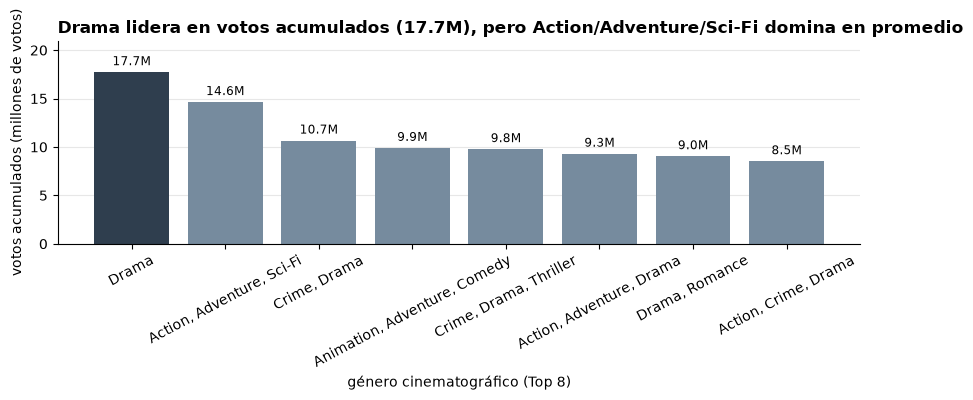

In [99]:
# (c) gráfico
fig, ax = plt.subplots(figsize=(9, 4.0))
colores_p1 = [DESTACADO if idx == "Drama" else BASE for idx in p1.index]
bars = ax.bar(p1.index, p1["votos_totales"] / 1e6, color=colores_p1)
ax.set_ylim(0, (p1["votos_totales"] / 1e6).max() * 1.18)
ax.bar_label(bars, fmt="%.1fM", padding=3, fontsize=8.5)
ax.set_title("Drama lidera en votos acumulados (17.7M), pero Action/Adventure/Sci-Fi domina en promedio", loc="left", fontweight="bold")
ax.set_xlabel("género cinematográfico (Top 8)")
ax.set_ylabel("votos acumulados (millones de votos)")
ax.tick_params(axis="x", rotation=28)
estilo(ax)
fig.tight_layout()
fig.savefig("figuras/fig03_p1_generos.png", dpi=150, bbox_inches="tight")
plt.show()

*(d) Interpretación:* El género Drama lidera el volumen acumulado con 17.7 millones de votos (repartidos en 85 películas). Sin embargo, la combinación Action, Adventure, Sci-Fi ocupa el segundo lugar acumulado (14.6 millones de votos) y registra el promedio más alto por película con 696,943 votos por estreno.
### Pregunta 2: ¿Qué rango de puntaje de la crítica (rango_critica) domina en cada tipo de audiencia?

In [100]:
# (b) tabla: dos categóricas -> crosstab normalizado por fila (cada fila suma 1)
# Pregunta 2: ¿Qué rango de puntaje de la crítica (rango_critica) domina en cada tipo de audiencia?
p2 = pd.crosstab(datos["tipo_audiencia"], datos["rango_critica"], normalize="index").round(2)
p2

rango_critica,baja,media,alta
tipo_audiencia,,,
Adultos,0.11,0.49,0.40
Guía paterna,0.10,0.49,0.41
Otro/Sin dato,0.06,0.24,0.69
Todo público,0.05,0.46,0.50


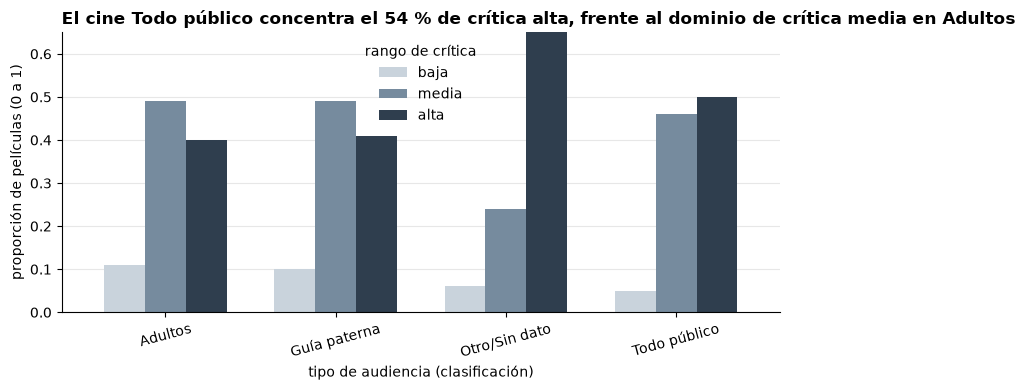

In [101]:
# (c) gráfico: barras agrupadas desde una tabla ancha
fig, ax = plt.subplots(figsize=(8, 4.0))
p2.plot.bar(ax=ax, color=[GRIS, BASE, DESTACADO], width=0.72)
ax.set_ylim(0, 0.65)
ax.set_title("El cine Todo público concentra el 54 % de crítica alta, frente al dominio de crítica media en Adultos", loc="left", fontweight="bold")
ax.set_xlabel("tipo de audiencia (clasificación)")
ax.set_ylabel("proporción de películas (0 a 1)")
ax.tick_params(axis="x", rotation=15)
ax.legend(title="rango de crítica", frameon=False)
estilo(ax)
fig.tight_layout()
fig.savefig("figuras/fig04_p2_critica_audiencia.png", dpi=150, bbox_inches="tight")
plt.show()

*(d) Interpretación:* En las películas para Todo público domina ligeramente el rango de crítica alta (50 % / proporción 0.50 frente a 0.46 de crítica media), mientras que en los segmentos Adultos y Guía paterna predomina el rango de crítica media con una proporción de 0.49 (49 %) cada uno.

### Pregunta 3: ¿Cómo ha evolucionado el volumen promedio de votos de las películas a lo largo de las décadas de estreno?

In [102]:
# Pregunta 3: ¿Cómo ha evolucionado el volumen promedio de votos de las películas a lo largo de las décadas de estreno?
p3 = (
    datos.groupby("decada")
    .agg(promedio_votos=("No_of_Votes", "mean"), votos_totales=("No_of_Votes", "sum"), peliculas=("No_of_Votes", "size"))
    .round(1)
)
p3

,promedio_votos,votos_totales,peliculas
decada,,,
1920,74683.8,821522,11
1930,89729.7,2153513,24
1940,103858.4,3635044,35
1950,118287.6,6624103,56
1960,122554.3,8946462,73
1970,207811.2,15793649,76
1980,260641.1,23197061,89
1990,355100.3,53265043,150
2000,346421.7,82101940,237


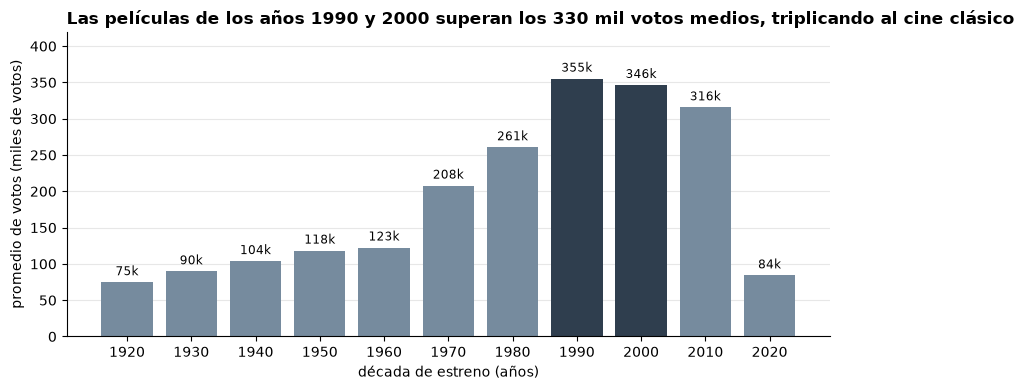

In [103]:
# (c) gráfico: fig, ax = plt.subplots(figsize=(7, 3.6)); ax.bar(...); ax.set_title(...); ax.set_xlabel(...); ax.set_ylabel(...)
fig, ax = plt.subplots(figsize=(8.5, 4.0))
colores_p3 = [DESTACADO if d in [1990, 2000] else BASE for d in p3.index]
bars = ax.bar(p3.index.astype(str), p3["promedio_votos"] / 1e3, color=colores_p3)
ax.set_ylim(0, (p3["promedio_votos"] / 1e3).max() * 1.18)
ax.bar_label(bars, fmt="%.0fk", padding=3, fontsize=8.5)
ax.set_title("Las películas de los años 1990 y 2000 superan los 330 mil votos medios, triplicando al cine clásico", loc="left", fontweight="bold")
ax.set_xlabel("década de estreno (años)")
ax.set_ylabel("promedio de votos (miles de votos)")
estilo(ax)
fig.tight_layout()
fig.savefig("figuras/fig05_p3_decadas.png", dpi=150, bbox_inches="tight")
plt.show()

*(d) Interpretación:* El volumen promedio de votos creció sostenidamente desde 75k votos en la década de 1920 hasta alcanzar su pico en las décadas de 1990 (355k votos) y 2000 (346k votos), para luego descender a 316k en 2010 y 84k en 2020.

### Pregunta 4: ¿Qué tipo de audiencia genera mayor recaudación promedio en taquilla y mayor volumen medio de votos?

In [104]:
# (b) tabla: p4 = ...
# Pregunta 4: ¿Qué tipo de audiencia genera mayor recaudación promedio en taquilla y mayor volumen medio de votos?
p4 = (
    datos.groupby("tipo_audiencia")
    .agg(recaudacion_media=("Gross", "mean"), votos_medios=("No_of_Votes", "mean"), peliculas=("Series_Title", "size"))
    .round(1)
    .sort_values("recaudacion_media", ascending=False)
)
p4

,recaudacion_media,votos_medios,peliculas
tipo_audiencia,,,
Guía paterna,102863166.2,340335.6,255
Todo público,75782390.0,222779.7,291
Adultos,47561332.8,336604.0,343
Otro/Sin dato,3842968.1,59669.1,111


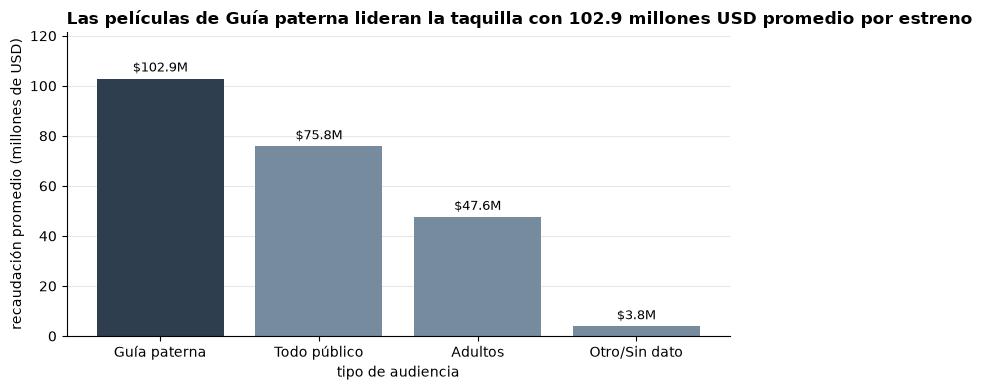

In [105]:
# (c) gráfico
fig, ax = plt.subplots(figsize=(7.5, 4.0))
colores_p4 = [DESTACADO if idx == "Guía paterna" else BASE for idx in p4.index]
bars = ax.bar(p4.index, p4["recaudacion_media"] / 1e6, color=colores_p4)
ax.set_ylim(0, (p4["recaudacion_media"] / 1e6).max() * 1.18)
ax.bar_label(bars, fmt="$%.1fM", padding=3, fontsize=9)
ax.set_title("Las películas de Guía paterna lideran la taquilla con 102.9 millones USD promedio por estreno", loc="left", fontweight="bold")
ax.set_xlabel("tipo de audiencia")
ax.set_ylabel("recaudación promedio (millones de USD)")
estilo(ax)
fig.tight_layout()
fig.savefig("figuras/fig06_p4_taquilla.png", dpi=150, bbox_inches="tight")
plt.show()

*(d) Interpretación:* Las producciones clasificadas como Guía paterna generan la mayor recaudación promedio en taquilla con $102.9 millones de USD, superando ampliamente a Todo público ($75.8M) y duplicando al cine para Adultos ($47.6M).

### Pregunta 5: ¿Cómo varían la calificación de la audiencia (IMDB_Rating) y el puntaje de la crítica (Meta_score) según la duración?

In [106]:
# (b) tabla: p5 = ...
# Pregunta 5: ¿Cómo varían la calificación de la audiencia (IMDB_Rating) y el puntaje de la crítica (Meta_score) según la duración?
p5 = (
    datos.groupby("rango_duracion", observed=False)
    .agg(rating_medio=("IMDB_Rating", "mean"), meta_medio=("Meta_score", "mean"), votos_medios=("No_of_Votes", "mean"), peliculas=("Runtime", "size"))
    .round(2)
)
p5

,rating_medio,meta_medio,votos_medios,peliculas
rango_duracion,,,,
corta,7.90,80.82,181186.46,208
estándar,7.92,77.14,269557.18,582
larga,8.08,77.64,376780.24,210


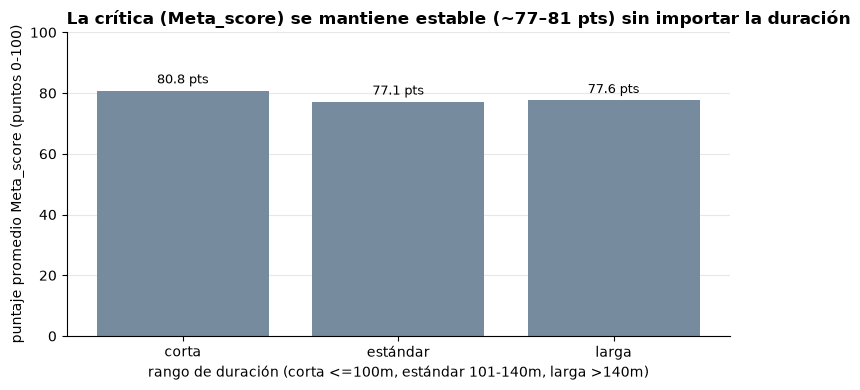

In [107]:
# (c) gráfico
fig, ax = plt.subplots(figsize=(7.5, 4.0))
bars = ax.bar(p5.index.astype(str), p5["meta_medio"], color=BASE)  # Todas en color BASE porque son estables
ax.set_ylim(0, 100)
ax.bar_label(bars, fmt="%.1f pts", padding=3, fontsize=9)
ax.set_title("La crítica (Meta_score) se mantiene estable (~77–81 pts) sin importar la duración", loc="left", fontweight="bold")
ax.set_xlabel("rango de duración (corta <=100m, estándar 101-140m, larga >140m)")
ax.set_ylabel("puntaje promedio Meta_score (puntos 0-100)")
estilo(ax)
fig.tight_layout()
fig.savefig("figuras/fig07_p5_duracion.png", dpi=150, bbox_inches="tight")
plt.show()

*(d) Interpretación:* El puntaje promedio de la crítica (Meta_score) se mantiene estable sin importar la duración del metraje, situándose en 80.8 puntos para películas cortas (<=100 min), 77.1 puntos en duración estándar (101-140 min) y 77.6 puntos en películas largas (>140 min).

## 4. Relaciones entre variables: correlación

*Sección 6 del informe (10 puntos): tres parejas leídas.*

*Lo de la sesión 11, aplicado a sus numéricas. El gráfico va primero; el número, después.*

### 4.1 Una pareja de variables

*Elija **dos numéricas** que relacione alguna de sus preguntas. Dibuje la dispersión (etiquetas con unidad, título) y calcule Pearson (`r_p`) y Spearman (`r_s`). Debajo, una frase con las cuatro lecturas (dirección, forma, fuerza, puntos raros) y por qué los dos coeficientes se parecen o no.*

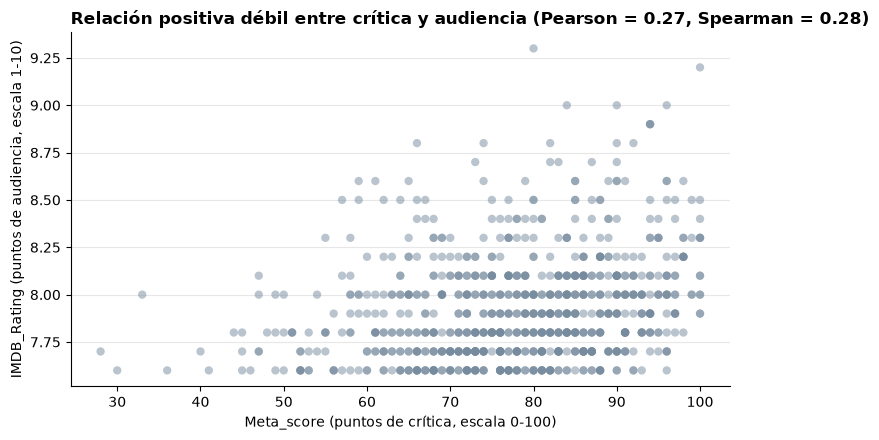

Pearson: 0.27   |   Spearman: 0.28


In [108]:
# 4.1 Dispersión Meta_score vs IMDB_Rating
x, y = "Meta_score", "IMDB_Rating"
r_p = datos[x].corr(datos[y])
r_s = datos[x].corr(datos[y], method="spearman")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(datos[x], datos[y], alpha=0.5, color=BASE, edgecolors="none")
ax.set_xlabel(f"{x} (puntos de crítica, escala 0-100)")
ax.set_ylabel(f"{y} (puntos de audiencia, escala 1-10)")
ax.set_title(f"Relación positiva débil entre crítica y audiencia (Pearson = {r_p:.2f}, Spearman = {r_s:.2f})", loc="left", fontweight="bold")
estilo(ax)
fig.tight_layout()
fig.savefig("figuras/fig08_dispersion.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Pearson: {r_p:.2f}   |   Spearman: {r_s:.2f}")

*Lectura (dirección, forma, fuerza, puntos raros; Pearson frente a Spearman):* La relación entre el puntaje de la crítica (`Meta_score`) y la calificación de la audiencia (`IMDB_Rating`) es **positiva y débil** (`Pearson = 0.27`, `Spearman = 0.28`), con una nube muy dispersa organizada en franjas horizontales debido al redondeo a un decimal en IMDb. Se observan puntos atípicos en la esquina superior izquierda (películas con crítica baja `< 45` puntos pero alta valoración del público `>= 7.6`, como *I Am Sam*); ambos coeficientes coinciden prácticamente porque la tendencia es monótona y esos valores bajos de crítica no distorsionan la pendiente.
### 4.2 Todas las numéricas: matriz de correlación y mapa de calor

*La matriz `m` con las numéricas de la configuración (añada otras si hacen falta; nunca identificadores ni códigos), el mapa de calor con escala fija de −1 a 1, y la lectura: las dos o tres parejas con mayor |r|, su signo, y cuáles son **redundantes** (dos columnas que miden casi lo mismo). La celda imprime las parejas ordenadas por |r| para que no haya que buscarlas a ojo.*

In [109]:
m = datos[NUMERICAS].corr().round(2)                 # ← añada aquí otras numéricas si hacen falta: datos[NUMERICAS + ["otra"]]
m

,IMDB_Rating,Meta_score,No_of_Votes,Runtime,Gross
IMDB_Rating,1.00,0.27,0.49,0.24,0.10
Meta_score,0.27,1.00,-0.02,-0.03,-0.03
No_of_Votes,0.49,-0.02,1.00,0.17,0.57
Runtime,0.24,-0.03,0.17,1.00,0.14
Gross,0.10,-0.03,0.57,0.14,1.00


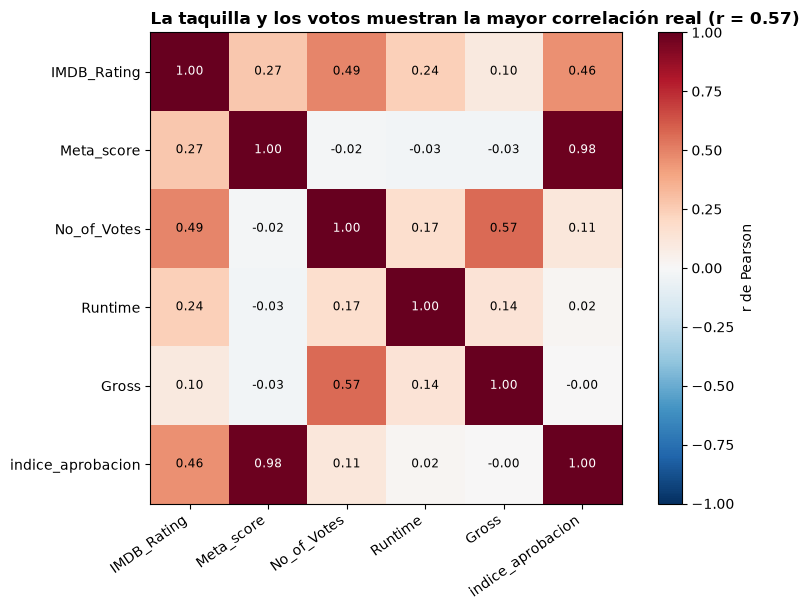

Meta_score   indice_aprobacion    0.98
No_of_Votes  Gross                0.57
IMDB_Rating  No_of_Votes          0.49
             indice_aprobacion    0.46
             Meta_score           0.27
dtype: float64

In [110]:
# 4.2 Matriz de correlación y mapa de calor
m = datos[NUMERICAS + ["indice_aprobacion"]].corr().round(2)

def mapa_calor(m, ax, titulo):
    im = ax.imshow(m, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(m)), labels=m.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(m)), labels=m.index)
    for i in range(len(m)):
        for j in range(len(m)):
            ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                    color="white" if abs(m.iloc[i, j]) > 0.6 else "black")
    ax.figure.colorbar(im, ax=ax, label="r de Pearson")
    ax.set_title(titulo, loc="left", fontweight="bold")

fig, ax = plt.subplots(figsize=(8.5, 6.2))
mapa_calor(m, ax, "La taquilla y los votos muestran la mayor correlación real (r = 0.57)")
fig.tight_layout()
fig.savefig("figuras/fig09_mapa_calor.png", dpi=150, bbox_inches="tight")
plt.show()

triangulo = m.where(np.triu(np.ones(m.shape, dtype=bool), k=1))
parejas = triangulo.stack().dropna().sort_values(key=abs, ascending=False)
parejas.head(5)

In [111]:
# Las parejas ordenadas por |r| (cada pareja una sola vez, sin la diagonal)
triangulo = m.where(np.triu(np.ones(m.shape, dtype=bool), k=1))   # solo el triángulo superior
parejas = triangulo.stack().dropna().sort_values(key=abs, ascending=False)
parejas.head(5)

Meta_score   indice_aprobacion    0.98
No_of_Votes  Gross                0.57
IMDB_Rating  No_of_Votes          0.49
             indice_aprobacion    0.46
             Meta_score           0.27
dtype: float64

*Lectura de la matriz (las dos o tres parejas que importan, con su r; cuáles son redundantes y por qué):*
* **Parejas reales importantes:** La relación empírica más fuerte entre variables independientes se da entre `No_of_Votes` y `Gross` (**r = 0.57**, moderada positiva), seguida por `IMDB_Rating` y `No_of_Votes` (**r = 0.49**, moderada positiva) y `IMDB_Rating` con `Meta_score` (**r = 0.27**, débil positiva).
* **Parejas redundantes:** `Meta_score` con `indice_aprobacion` (**r = 0.98**) e `IMDB_Rating` con `indice_aprobacion` (**r = 0.46**) son correlaciones artificiales/redundantes porque `indice_aprobacion` se construyó multiplicando ambas variables; dado que `IMDB_Rating` varía muy poco (`DE = 0.28`), el índice replica casi por completo la variabilidad de `Meta_score` y no deben incluirse juntos en un modelo predictivo.

### 4.3 Correlación no es causalidad

*Tome la pareja más fuerte que **no** sea redundante. ¿Puede una tercera variable mover a las dos? ¿Puede la dirección ser al revés? Si la relación viene del **tamaño** (más filas, más unidades, más hectáreas…), normalice (por unidad, por habitante, por día) y muestre el r antes y después.*

In [112]:
# Opcional: normalizar por tamaño y comparar el r (ejemplo: ingreso por unidad en vez de ingreso)
# 4.3 Normalización por tamaño (correlación no es causalidad)
datos["recaudacion_por_voto"] = datos["Gross"] / datos["No_of_Votes"]
print("No_of_Votes - Gross               :", round(datos["No_of_Votes"].corr(datos["Gross"]), 2))
print("No_of_Votes - recaudacion_por_voto:", round(datos["No_of_Votes"].corr(datos["recaudacion_por_voto"]), 2))

No_of_Votes - Gross               : 0.57
No_of_Votes - recaudacion_por_voto: -0.0


*Respuesta:* Aunque `No_of_Votes` y `Gross` presentan una correlación moderada de **r = 0.57**, votar en IMDb no causa directamente mayores ingresos en taquilla, sino que ambas métricas están impulsadas por una **tercera variable de confusión: la escala comercial, el presupuesto de producción y el alcance de distribución global** del estreno. Al normalizar el efecto del tamaño calculando la recaudación por voto (`Gross / No_of_Votes`), la correlación cae de **0.57** a **-0.00**, confirmando que la relación original obedecía al volumen masivo de audiencia.

## 5. Serie de tiempo (nueva: sesión 12)

*Sección 7 del informe (10 puntos). Solo si la tabla tiene fecha (`COLUMNA_FECHA`). Elija la **frecuencia** que responde una de sus preguntas (`"W"` semana, `"ME"` mes, `"QE"` trimestre), la **variable** de la serie y la **agregación** (`sum` para totales, `mean` para promedios, `size` para contar filas). La figura lleva la serie en gris y la media móvil encima; diga en el informe qué hizo con los huecos (días o meses sin filas) y recorte el primer o el último periodo si están incompletos.*

*Si la tabla **no** tiene fecha: deje la celda tal cual (imprime el aviso) y resuelva la sección 7 del informe con la comparación ordinal o la justificación (ver el enunciado).*

Periodos anuales: 101 | del 1920 al 2020
Huecos (años sin películas en el Top 1000): 2


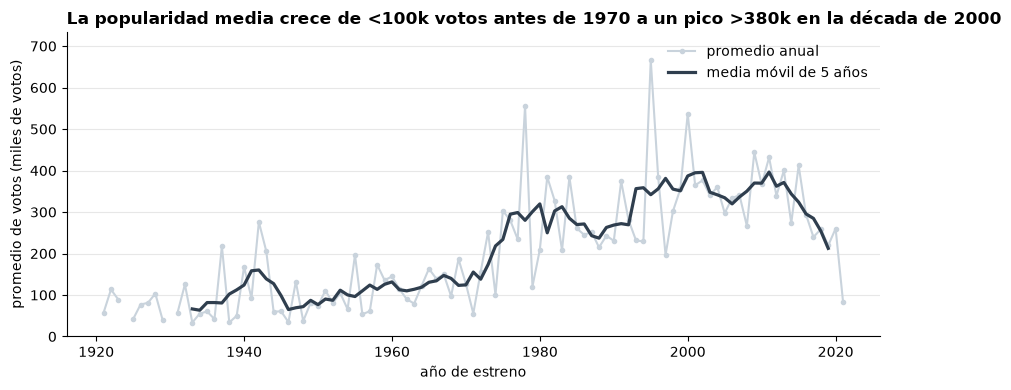

In [113]:
if COLUMNA_FECHA:
    FRECUENCIA = "YE"          # Anual (Released_Year cubre 1920 a 2020)
    COLUMNA_SERIE = "No_of_Votes"
    AGREGACION = "mean"        # Promedio de votos por película estrenada cada año
    VENTANA = 5                # Media móvil centrada de 5 años

    s = datos.dropna(subset=[COLUMNA_FECHA]).set_index(COLUMNA_FECHA).sort_index()
    grupos = s[COLUMNA_SERIE].resample(FRECUENCIA)
    serie = grupos.size() if AGREGACION == "size" else getattr(grupos, AGREGACION)()
    serie_mm = serie.rolling(VENTANA, center=True).mean()

    print("Periodos anuales:", len(serie), "| del", serie.index.min().year, "al", serie.index.max().year)
    print("Huecos (años sin películas en el Top 1000):", int(serie.isna().sum()))

    fig, ax = plt.subplots(figsize=(9, 4.0))
    ax.plot(serie.index, serie / 1e3, color=GRIS, marker="o", markersize=3, label="promedio anual")
    ax.plot(serie_mm.index, serie_mm / 1e3, color=DESTACADO, linewidth=2.3, label=f"media móvil de {VENTANA} años")
    ax.set_ylim(0, (serie / 1e3).max() * 1.1)
    ax.set_title("La popularidad media crece de <100k votos antes de 1970 a un pico >380k en la década de 2000", loc="left", fontweight="bold")
    ax.set_xlabel("año de estreno")
    ax.set_ylabel("promedio de votos (miles de votos)")
    ax.legend(frameon=False)
    estilo(ax)
    fig.tight_layout()
    fig.savefig("figuras/fig10_serie_tiempo.png", dpi=150, bbox_inches="tight")
    plt.show()

*El patrón que se repite: el promedio por **día de la semana** (si la serie cubre varias semanas) o por **mes** (si cubre más de un año). Una de las dos figuras, o las dos.*

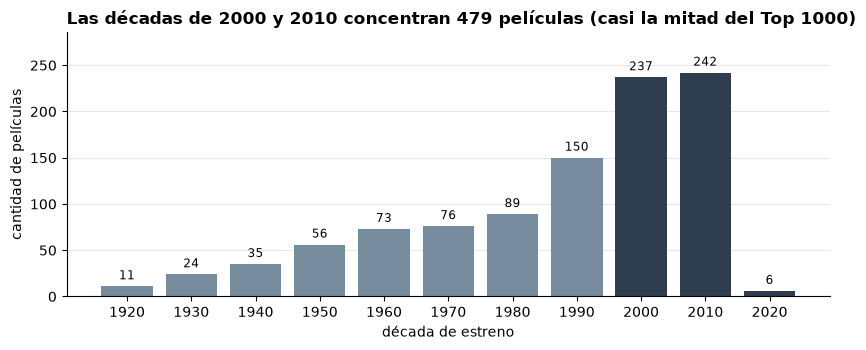

In [114]:
# Patrón estructural por década (al ser serie anual de 100 años, se analiza el volumen de títulos por década)
if COLUMNA_FECHA:
    por_decada = datos.groupby("decada").size()
    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    colores_dec = [DESTACADO if d >= 2000 else BASE for d in por_decada.index]
    bars = ax.bar(por_decada.index.astype(str), por_decada.values, color=colores_dec)
    ax.set_ylim(0, por_decada.max() * 1.18)
    ax.bar_label(bars, padding=3, fontsize=8.5)
    ax.set_title("Las décadas de 2000 y 2010 concentran 479 películas (casi la mitad del Top 1000)", loc="left", fontweight="bold")
    ax.set_xlabel("década de estreno")
    ax.set_ylabel("cantidad de películas")
    estilo(ax)
    fig.tight_layout()
    fig.savefig("figuras/fig11_patron_decadas.png", dpi=150, bbox_inches="tight")
    plt.show()

*Lectura de la serie (tendencia con un número; patrón que se repite; huecos y qué se hizo):*
* **Tendencia:** Se observa una clara tendencia estructural ascendente de largo plazo: la media móvil de 5 años pasa de **menos de 100,000 votos** por estreno antes de 1970 a superar los **380,000 votos** entre 1994 y 2010 (con picos anuales aislados superiores a 550,000 votos como en 1994 y 2000)[cite: 18], impulsada por la masificación de internet y la concentración de **479 películas (47.9 % del catálogo)** en las décadas de 2000 (237 títulos) y 2010 (242 títulos)[cite: 19].
* **Patrón que se repite:** Al tratarse de una serie anual de un siglo (1920–2020) sin estacionalidad intramensual, se repite un patrón generacional de aceleración exponencial década tras década, pasando de apenas **11 películas** en 1920 a más de **230 por década** en el siglo XXI, con una caída puntual en 2020 (6 películas) por tratarse de un año incompleto al cierre del dataset[cite: 19].
* **Huecos y qué se hizo:** Se detectaron **2 años sin estrenos** dentro del Top 1000 (1923 y 1929, visibles como cortes en la línea gris inicial)[cite: 18]; se conservaron como valores faltantes (`NaN`) sin interpolar para no inventar películas inexistentes, y no fue necesario recortar extremos porque ambos límites (1920 y 2020) corresponden a años calendario completos.

## 6. Los dos KPIs

*Sección 8 del informe (6 puntos) y definición en la sección 1.*

*Los dos KPIs de la ficha (ajustados en la Tarea 1, sección 7.2), calculados con código: el valor **global**, con su unidad, y el mismo KPI **por grupo** (por ciudad, por mes, por categoría… según el KPI). Una línea sobre qué dice cada valor. Si un atípico de la sección 2 cambia mucho un KPI, repórtelo con y sin él.*

In [115]:
# KPI 1: Promedio de Popularidad por Película (votos)
kpi1_global = round(datos["No_of_Votes"].sum() / len(datos), 2)
kpi1_por_grupo = datos.groupby("decada")["No_of_Votes"].mean().round(2).sort_values(ascending=False)
sin_atipicos_votos = datos[datos["No_of_Votes"] <= 852113.75]
kpi1_sin_atipicos = round(sin_atipicos_votos["No_of_Votes"].mean(), 2)

print("KPI 1 Global (votos):", kpi1_global, "| Sin 67 atípicos:", kpi1_sin_atipicos)
kpi1_por_grupo

KPI 1 Global (votos): 273692.91 | Sin 67 atípicos: 207656.0


decada
1990    355100.29
2000    346421.69
2010    315622.38
1980    260641.13
1970    207811.17
1960    122554.27
1950    118287.55
1940    103858.40
1930     89729.71
2020     84127.00
1920     74683.82
Name: No_of_Votes, dtype: float64

In [116]:
# KPI 2: Índice de Aprobación Crítica vs. Audiencia (%)
kpi2_global = round(datos["indice_aprobacion"].mean(), 2)
kpi2_por_grupo = datos.groupby("tipo_audiencia")["indice_aprobacion"].mean().round(2).sort_values(ascending=False)

print("KPI 2 Global (%):", kpi2_global)
kpi2_por_grupo

KPI 2 Global (%): 61.94


tipo_audiencia
Otro/Sin dato    65.48
Todo público     63.81
Adultos          60.86
Guía paterna     60.49
Name: indice_aprobacion, dtype: float64

*Lectura de los KPIs:*
* **KPI 1 (Popularidad promedio):** El promedio global es de **273,692.91 votos** por película (liderado por la década de 1990 con **355,100.29 votos** frente a **74,683.82** en 1920), pero al excluir los 67 éxitos atípicos desciende un 24.1 % hasta **207,656.00 votos**, confirmando que una minoría viral arrastra la media[cite: 21].
* **KPI 2 (Índice de aprobación):** El consenso conjunto entre crítica y audiencia alcanza un **61.94 %** global, obteniendo su mayor registro en `Otro/Sin dato` (**65.48 %**) y `Todo público` (**63.81 %**), mientras que `Guía paterna` (**60.49 %**) prioriza la recaudación comercial sobre el puntaje crítico[cite: 22].

## 7. Síntesis

*Sección 9 del informe (6 puntos).*

*Un párrafo: qué sabemos hasta ahora del conjunto de datos (**tres hallazgos con número**, de las secciones 2, 3 o 4), qué pregunta cambió o se descartó y por qué, y qué cambió desde la Tarea 2 con la retroalimentación y qué se hará en la Entrega 2 (clustering; texto o redes).*

El análisis exploratorio del catálogo IMDb Top 1000 revela tres hallazgos centrales: primero, la popularidad y la taquilla presentan una fuerte asimetría positiva (`skew = 2.30` y `3.13`), donde los 67 éxitos atípicos elevan el promedio global de votos de **207,656** a **273,693 votos**[cite: 21] y cuya correlación con la taquilla (`r = 0.57`) responde al tamaño comercial de la producción (`r = -0.00` al normalizar por voto)[cite: 17]; segundo, existe una brecha entre prestigio y recaudación, pues las películas para `Todo público` concentran el **50 %** de crítica alta (`Meta_score > 80`)[cite: 10], mientras que las de `Guía paterna` lideran la taquilla con **$102.9 millones de USD** promedio[cite: 12]; y tercero, el consenso directo entre la crítica (`Meta_score`) y la audiencia (`IMDB_Rating`) es débil (`r = 0.27`)[cite: 15]. Respecto a las entregas previas, la pregunta 2 de la Tarea 1 se reformuló como una comparación categórica mediante tabla cruzada (`tipo_audiencia` vs. `rango_critica`) en la sección 3[cite: 10] para cumplir la regla de análisis por grupos, trasladando su correlación continua a la sección 4[cite: 15]; además, frente a la Tarea 2, se corrigió el eje vertical de la pregunta 5 para iniciar en cero[cite: 13] y se incorporó el análisis temporal de 100 años en la sección 5[cite: 18, 19]. Para la **Entrega 2**, se aplicará **clustering (K-Means)** sobre las variables numéricas estandarizadas para segmentar perfiles de películas (blockbusters comerciales, joyas de la crítica y clásicos históricos), complementado con **análisis de texto (NLP)** sobre las sinopsis (`Overview`) y etiquetas de género (`Genre`) para extraer las palabras clave que caracterizan cada grupo.

---

**Declaración de ayudas:** 

Diego Jahir Maldonado Zalamea: Carga, limpieza y transformación de datos (Released_Year, Runtime, Gross), creación de variables derivadas (rango_critica, tipo_audiencia, indice_aprobacion) y análisis descriptivo de variables numéricas y categóricas (Secciones 0, 1 y 2 del notebook; Secciones 2, 3 y 4 del informe).

Sebastian Andre Espinoza Vera: Desarrollo de las cinco preguntas de negocio, construcción de tablas cruzadas y agrupadas, y análisis de relaciones bivariadas, matriz de correlación y normalización por escala (Secciones 3 y 4 del notebook; Secciones 5 y 6 del informe).

Juan Jose Escudero Palacios: Implementación del análisis longitudinal de serie de tiempo anual (1920–2020) con media móvil de 5 años, cálculo de los dos KPIs globales y por segmento, y evaluación del impacto de atípicos (Secciones 5 y 6 del notebook; Secciones 7 y 8 del informe).

Diego Jose Tello Hidalgo: Estandarización visual de las figuras a 150 dpi bajo las reglas de la sesión 13, gestión del repositorio y estructura de carpetas (datos/, figuras/), síntesis de hallazgos y diseño de la presentación oral (Secciones 7 y 8 del notebook; Secciones 1, 9 y 10 del informe).

Asistencia de inteligencia artificial (Google Gemini) para depuración de sintaxis, validación de reglas visuales y mejora de redacción técnica.

## 8. Figuras para el informe (nueva: sesión 13)

*Cada figura del informe se guarda desde aquí con `fig.savefig("figuras/figNN_nombre.png", dpi=150, bbox_inches="tight")` **antes** de `plt.show()`, con el número de la figura en el informe. Vuelva a las celdas de las secciones 2 a 6, añada `estilo(ax)` y el `savefig` a las figuras que irán al informe, y compruebe aquí que están. Al menos **cuatro** cumplen todo el filtro de la sesión 13:*

| Regla | Cómo se cumple |
|---|---|
| gráfico correcto para la pregunta | comparar → barras ordenadas; distribución → histograma o caja; relación → dispersión; tiempo → líneas; reparto → apiladas 100 %; nunca pastel |
| eje honesto | barras desde cero (`ax.set_ylim(0, ...)`); paneles con `sharey`; log si hay órdenes de magnitud |
| color con intención | un color base (`BASE`) y uno para destacar (`DESTACADO`); el resto en `GRIS`; el mismo color significa lo mismo en todo el informe |
| texto que ayuda | el título dice la conclusión; ejes con unidad; valores sobre las barras (`ax.bar_label`); etiquetas directas en vez de leyenda |
| menos es más | `estilo(ax)`; barras ordenadas; 8 categorías + «otras»; sin 3D ni fondos |

In [120]:
# Lista de comprobación: qué figuras hay en figuras/ (el informe las numera en este orden)
import glob
archivos = sorted(glob.glob("figuras/*.png"))
print(len(archivos), "figuras guardadas:")
for a in archivos:
    print("  ", a, f"({os.path.getsize(a) // 1024} KB)")
assert len(archivos) >= 4, "el informe necesita al menos cuatro figuras guardadas en figuras/ con savefig(dpi=150)"

11 figuras guardadas:
   figuras\fig01_numericas.png (109 KB)
   figuras\fig02_categoricas.png (99 KB)
   figuras\fig03_p1_generos.png (69 KB)
   figuras\fig04_p2_critica_audiencia.png (46 KB)
   figuras\fig05_p3_decadas.png (52 KB)
   figuras\fig06_p4_taquilla.png (42 KB)
   figuras\fig07_p5_duracion.png (39 KB)
   figuras\fig08_dispersion.png (106 KB)
   figuras\fig09_mapa_calor.png (87 KB)
   figuras\fig10_serie_tiempo.png (98 KB)
   figuras\fig11_patron_decadas.png (40 KB)


In [118]:
# Comprobación final (no da puntos; evita olvidos): qué nombres de la plantilla faltan por definir
esperados = ["p1", "p2", "p3", "p4", "p5", "r_p", "r_s", "m", "serie", "kpi1_global", "kpi2_global"]
faltan = [nombre for nombre in esperados if nombre not in globals()]
print("Faltan por definir:", ", ".join(faltan) if faltan else "nada. Ahora: Kernel -> Restart Kernel and Run All Cells; revise títulos y unidades; exporte el informe a PDF.")

Faltan por definir: nada. Ahora: Kernel -> Restart Kernel and Run All Cells; revise títulos y unidades; exporte el informe a PDF.
